# Sleep Staging — 04: Classical Baseline Models and Feature Reduction

**Objetivo:** comparar modelos clásicos y distintas estrategias simples de selección de features sobre las features tabulares generadas en la notebook anterior.

**Entrada principal:**
- `../data/processed/features_full.parquet`

**Experimentos:**

1. Todas las features.
2. Selección supervisada con ANOVA.
3. Selección supervisada con información mutua.

**Modelos:**
- Dummy classifier.
- SGD Logistic.
- Random Forest.

La separación y la validación se realizan **por sujeto**. Toda transformación que utiliza información estadística o etiquetas se ajusta dentro de cada fold para evitar leakage.


---
## 0. Setup

Se limitan los threads nativos antes de importar NumPy y scikit-learn para reducir el riesgo de conflictos entre OpenBLAS, MKL y OpenMP.


In [2]:
import os

for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[variable] = "1"

from pathlib import Path
from functools import partial
import gc
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import psutil

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from IPython.display import display, Image

from scipy.stats import kruskal

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (
    SelectKBest,
    VarianceThreshold,
    f_classif,
    mutual_info_classif,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# ── Rutas ─────────────────────────────────────────────────────
DATA_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../reports/results")

FEATURES_PATH = DATA_DIR / "features_full.parquet"
CV_RESULTS_PATH = RESULTS_DIR / "baseline_feature_reduction_cv.csv"
HOLDOUT_RESULTS_PATH = RESULTS_DIR / "baseline_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "baseline_holdout_predictions.parquet"
MODEL_PATH = MODELS_DIR / "baseline_best_model.joblib"
KRUSKAL_PATH = RESULTS_DIR / "kruskal_feature_ranking.csv"
SPLIT_PATH = RESULTS_DIR / "baseline_subject_split.json"

for directory in (FIGURES_DIR, MODELS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Si NB3 fue actualizada, los artefactos previos de NB4 dejan de ser válidos.
ARTIFACT_PATHS = [
    CV_RESULTS_PATH,
    HOLDOUT_RESULTS_PATH,
    PREDICTIONS_PATH,
    MODEL_PATH,
    KRUSKAL_PATH,
    SPLIT_PATH,
]

if FEATURES_PATH.exists():
    features_mtime = FEATURES_PATH.stat().st_mtime
    stale = any(
        path.exists() and path.stat().st_mtime < features_mtime
        for path in ARTIFACT_PATHS
    )

    if stale:
        print("NB3 fue actualizada: se eliminan artefactos previos de NB4.")
        for path in ARTIFACT_PATHS:
            if path.exists():
                path.unlink()

# ── Parámetros ────────────────────────────────────────────────
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 3

ANOVA_K = 50
MI_K = 50
SELECTION_TOLERANCE = 0.005

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

print("Setup completado.")
print("Threads numéricos limitados a 1.")


Setup completado.
Threads numéricos limitados a 1.


---
## 1. Carga y validación del dataset


In [3]:
if not FEATURES_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo:\n{FEATURES_PATH.resolve()}\n"
        "Ejecutá primero la notebook 03 de feature engineering."
    )

features_df = pd.read_parquet(FEATURES_PATH)

METADATA_COLS = [
    "epoch_global",
    "epoch_in_subject",
    "source_epoch_index",
    "recording_onset_s",
    "label",
    "subject",
    "qc_status",
    "qc_reason",
    "review_mask",
]

missing_metadata = [
    column
    for column in METADATA_COLS
    if column not in features_df.columns
]

if missing_metadata:
    raise ValueError(
        f"Faltan columnas de metadata: {missing_metadata}"
    )

FEATURE_COLS = [
    column
    for column in features_df.columns
    if column not in METADATA_COLS
]

X = features_df[FEATURE_COLS].astype(np.float32)
y = features_df["label"].astype(np.int8)
groups = features_df["subject"].astype(str)

assert len(X) == len(y) == len(groups)
assert set(y.unique()).issubset(STAGE_MAP)
assert not set(METADATA_COLS) & set(FEATURE_COLS)

print(f"Dataset:      {features_df.shape}")
print(f"Features:     {len(FEATURE_COLS)}")
print(f"Epochs:       {len(features_df)}")
print(f"Sujetos:      {groups.nunique()}")
print(f"Memoria:      {features_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Dataset:      (135471, 195)
Features:     186
Epochs:       135471
Sujetos:      149
Memoria:      107.3 MB


### 1.1 Distribución de clases


,epochs,percentage
label,,
W,23493,17.34
N1,14846,10.96
N2,49455,36.51
N3,26671,19.69
REM,21006,15.51


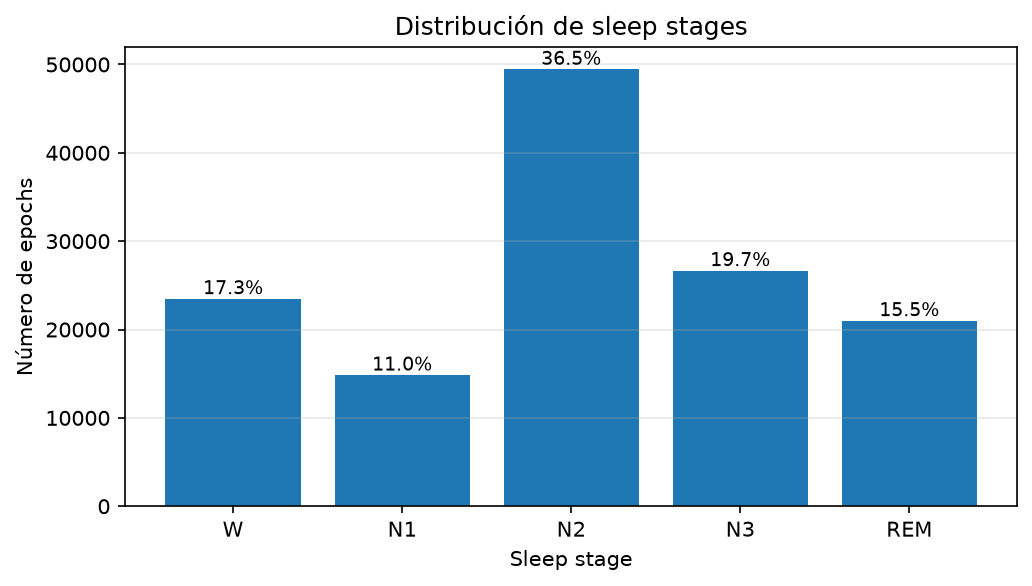

In [4]:
stage_summary = (
    y.value_counts()
    .sort_index()
    .rename(index=STAGE_MAP)
    .to_frame("epochs")
)

stage_summary["percentage"] = (
    100 * stage_summary["epochs"] / stage_summary["epochs"].sum()
)

display(stage_summary.round(2))

CLASS_DISTRIBUTION_PATH = FIGURES_DIR / "baseline_stage_distribution.png"

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(stage_summary.index, stage_summary["epochs"])

ax.set_title("Distribución de sleep stages")
ax.set_xlabel("Sleep stage")
ax.set_ylabel("Número de epochs")
ax.grid(axis="y", alpha=0.3)

for bar, percentage in zip(bars, stage_summary["percentage"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(
    CLASS_DISTRIBUTION_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(CLASS_DISTRIBUTION_PATH),
        width=750,
    )
)


---
## 2. División por sujeto

Se reserva un conjunto final de sujetos no vistos. Todas las comparaciones de configuración se realizan únicamente sobre el conjunto de entrenamiento mediante `GroupKFold`.


In [5]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

train_subjects = set(groups_train.unique())
test_subjects = set(groups_test.unique())

assert train_subjects.isdisjoint(test_subjects)

with open(SPLIT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        {
            "random_state": RANDOM_STATE,
            "test_size": TEST_SIZE,
            "train_subjects": sorted(train_subjects),
            "test_subjects": sorted(test_subjects),
        },
        file,
        indent=2,
        ensure_ascii=False,
    )

print(f"Train epochs:     {len(X_train)}")
print(f"Test epochs:      {len(X_test)}")
print(f"Train sujetos:    {len(train_subjects)}")
print(f"Test sujetos:     {len(test_subjects)}")
print(f"Solapamiento:     {len(train_subjects & test_subjects)}")
print(f"Split guardado:   {SPLIT_PATH.resolve()}")


Train epochs:     108839
Test epochs:      26632
Train sujetos:    119
Test sujetos:     30
Solapamiento:     0
Split guardado:   C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_subject_split.json


In [6]:
# Liberar objetos que ya no se necesitan para la validación
del X
gc.collect()

process = psutil.Process(os.getpid())

print(f"RAM del kernel: {process.memory_info().rss / 1024**3:.2f} GB")
print(f"RAM disponible: {psutil.virtual_memory().available / 1024**3:.2f} GB")


RAM del kernel: 0.43 GB
RAM disponible: 16.25 GB


---
## 3. Análisis exploratorio no paramétrico

Kruskal–Wallis se usa únicamente como diagnóstico exploratorio. Para reducir la pseudorreplicación, el análisis se realiza sobre la media de cada feature por sujeto y stage, no sobre todos los epochs individuales.

Este ranking **no se utiliza directamente para entrenar los modelos**.


In [7]:
subject_stage_means = (
    features_df.loc[train_idx, ["subject", "label"] + FEATURE_COLS]
    .groupby(["subject", "label"], observed=True)[FEATURE_COLS]
    .mean()
    .reset_index()
)

kruskal_rows = []

for feature in FEATURE_COLS:
    stage_values = [
        group[feature].dropna().to_numpy()
        for _, group in subject_stage_means.groupby("label", observed=True)
    ]

    stage_values = [
        values for values in stage_values
        if len(values) > 0
    ]

    try:
        statistic, p_value = kruskal(*stage_values)
    except ValueError:
        statistic, p_value = np.nan, np.nan

    kruskal_rows.append({
        "feature": feature,
        "kruskal_h": statistic,
        "p_value": p_value,
    })

kruskal_df = (
    pd.DataFrame(kruskal_rows)
    .sort_values("kruskal_h", ascending=False)
    .reset_index(drop=True)
)

kruskal_df.to_csv(KRUSKAL_PATH, index=False)

display(kruskal_df.head(20).round(5))
print("Ranking guardado:", KRUSKAL_PATH.resolve())


,feature,kruskal_h,p_value
0,EEG C3-M2__ratio_sigma_beta,422.910645,0.0
1,EEG C4-M1__ratio_sigma_beta,418.235596,0.0
2,EEG C3-M2__beta_rel,408.274170,0.0
3,EEG C3-M2__zcr,388.052246,0.0
4,EEG C4-M1__beta_rel,383.355713,0.0
5,EEG F4-M1__ratio_sigma_beta,381.799316,0.0
6,EEG F4-M1__beta_rel,380.671173,0.0
7,EEG F4-M1__beta_abs,377.471680,0.0
8,EEG C4-M1__zcr,376.409668,0.0
9,EOG E1-M2__beta_abs,372.423309,0.0


Ranking guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\kruskal_feature_ranking.csv


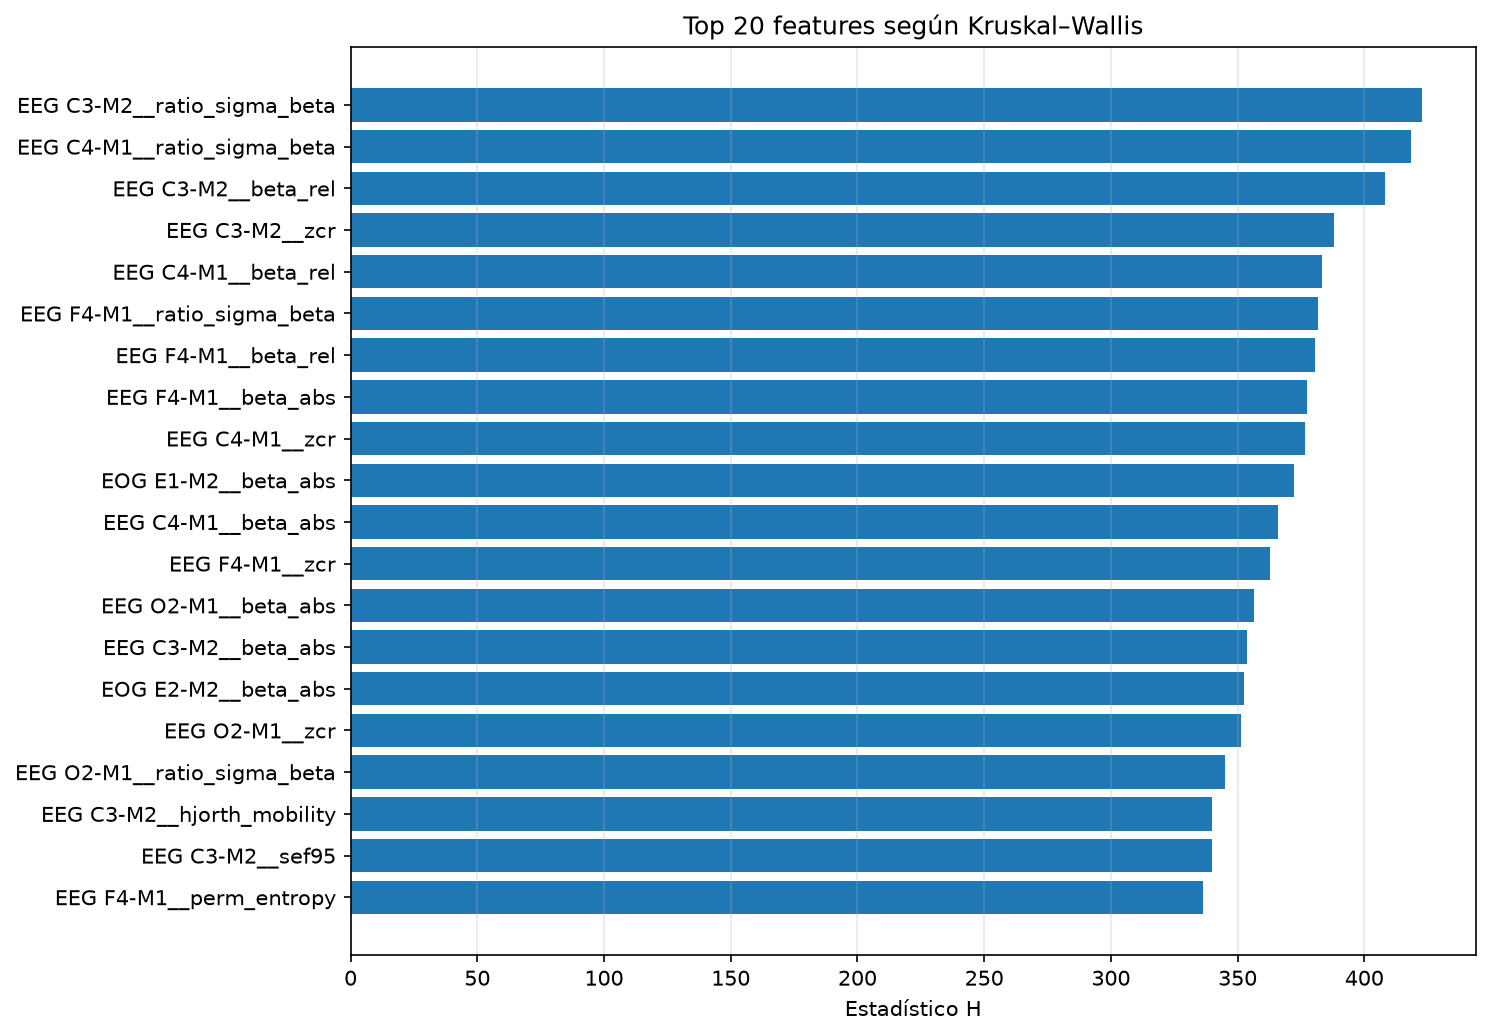

In [8]:
KRUSKAL_PLOT_PATH = FIGURES_DIR / "kruskal_top_features.png"

top_kruskal = (
    kruskal_df
    .dropna(subset=["kruskal_h"])
    .head(20)
    .sort_values("kruskal_h")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_kruskal["feature"],
    top_kruskal["kruskal_h"],
)

ax.set_title("Top 20 features según Kruskal–Wallis")
ax.set_xlabel("Estadístico H")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    KRUSKAL_PLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(KRUSKAL_PLOT_PATH),
        width=950,
    )
)


In [9]:
del subject_stage_means
gc.collect()


30

---
## 4. Pipelines y configuraciones

La imputación, el descarte de features constantes, la selección y el escalado se ajustan dentro de cada fold.

### Configuraciones comparadas

- Dummy con todas las features.
- SGD Logistic con todas las features.
- SGD Logistic con ANOVA top 50.
- SGD Logistic con información mutua top 50.
- Random Forest con todas las features.
- Random Forest con ANOVA top 50.

Chi-cuadrado no se utiliza porque las features son continuas y varias pueden tomar valores negativos.


In [10]:
def mutual_information_score(X_data, y_data):
    """Información mutua reproducible y con un solo thread."""
    return mutual_info_classif(
        X_data,
        y_data,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

def make_sgd_pipeline(selector=None):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(threshold=1e-12)),
    ]

    if selector is not None:
        steps.append(("selector", selector))

    steps.extend([
        ("scaler", StandardScaler()),
        (
            "model",
            SGDClassifier(
                loss="log_loss",
                penalty="l2",
                alpha=1e-4,
                max_iter=1000,
                tol=1e-3,
                class_weight="balanced",
                early_stopping=False,
                n_jobs=1,
                random_state=RANDOM_STATE,
            ),
        ),
    ])

    return Pipeline(steps)


def make_forest_pipeline(selector=None):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold(threshold=1e-12)),
    ]

    if selector is not None:
        steps.append(("selector", selector))

    steps.append(
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=5,
                max_features="sqrt",
                class_weight="balanced_subsample",
                n_jobs=1,
                random_state=RANDOM_STATE,
            ),
        )
    )

    return Pipeline(steps)


experiments = {
    "Dummy | All features": DummyClassifier(
        strategy="most_frequent"
    ),
    "SGD | All features": make_sgd_pipeline(),
    "SGD | ANOVA top 50": make_sgd_pipeline(
        selector=SelectKBest(
            score_func=f_classif,
            k=min(ANOVA_K, len(FEATURE_COLS)),
        )
    ),
    "SGD | Mutual information top 50": make_sgd_pipeline(
        selector=SelectKBest(
            score_func=mutual_information_score,
            k=min(MI_K, len(FEATURE_COLS)),
        )
    ),
    "Random Forest | All features": make_forest_pipeline(),
    "Random Forest | ANOVA top 50": make_forest_pipeline(
        selector=SelectKBest(
            score_func=f_classif,
            k=min(ANOVA_K, len(FEATURE_COLS)),
        )
    ),
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro",
}

group_cv = GroupKFold(n_splits=N_SPLITS)

print("Configuraciones:")
for name in experiments:
    print(" -", name)


Configuraciones:
 - Dummy | All features
 - SGD | All features
 - SGD | ANOVA top 50
 - SGD | Mutual information top 50
 - Random Forest | All features
 - Random Forest | ANOVA top 50


---
## 5. Comparación con GroupKFold

Los experimentos se ejecutan secuencialmente. Los resultados se guardan después de cada configuración para no perder el progreso si una ejecución se interrumpe.


In [11]:
# Recuperar resultados ya guardados
if CV_RESULTS_PATH.exists():
    cv_results = pd.read_csv(CV_RESULTS_PATH)
    cv_rows = cv_results.to_dict("records")

    completed_experiments = set(
        cv_results["experiment"]
    )

    print("Resultados recuperados:")
    for experiment in completed_experiments:
        print(" -", experiment)

else:
    cv_rows = []
    completed_experiments = set()

for experiment_name, estimator in experiments.items():

    if experiment_name in completed_experiments:
        print(f"\nOmitiendo: {experiment_name}")
        print("Ya fue evaluado.")
        continue

    print(f"\nEvaluando: {experiment_name}")

    process = psutil.Process(os.getpid())

    print(
        f"RAM antes del ajuste: "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
    )

    row = {
        "experiment": experiment_name,
        "fit_time_mean": scores["fit_time"].mean(),
        "fit_time_std": scores["fit_time"].std(),
    }

    for metric in scoring:
        values = scores[f"test_{metric}"]

        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    cv_rows.append(row)

    cv_results = (
        pd.DataFrame(cv_rows)
        .sort_values(
            "f1_macro_mean",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    # Guardar inmediatamente
    cv_results.to_csv(
        CV_RESULTS_PATH,
        index=False,
    )

    print(
        f"Macro-F1: "
        f"{row['f1_macro_mean']:.4f} "
        f"± {row['f1_macro_std']:.4f}"
    )

    del scores
    gc.collect()

if not cv_rows:
    raise RuntimeError(
        "No hay resultados disponibles."
    )

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values(
        "f1_macro_mean",
        ascending=False,
    )
    .drop_duplicates(
        subset="experiment",
        keep="last",
    )
    .reset_index(drop=True)
)

cv_results.to_csv(
    CV_RESULTS_PATH,
    index=False,
)

display(cv_results.round(4))

print(
    "Resultados guardados:",
    CV_RESULTS_PATH.resolve(),
)


Evaluando: Dummy | All features
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.1061 ± 0.0018

Evaluando: SGD | All features
RAM antes del ajuste: 0.45 GB
Macro-F1: 0.6928 ± 0.0039

Evaluando: SGD | ANOVA top 50
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.6591 ± 0.0022

Evaluando: SGD | Mutual information top 50
RAM antes del ajuste: 0.44 GB
Macro-F1: 0.6523 ± 0.0020

Evaluando: Random Forest | All features
RAM antes del ajuste: 0.45 GB
Macro-F1: 0.7024 ± 0.0068

Evaluando: Random Forest | ANOVA top 50
RAM antes del ajuste: 0.45 GB
Macro-F1: 0.6685 ± 0.0015


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,131.1848,0.2354,0.7357,0.0051,0.7043,0.0066,0.7024,0.0068
1,SGD | All features,25.0004,0.4046,0.7246,0.0047,0.7057,0.0069,0.6928,0.0039
2,Random Forest | ANOVA top 50,67.1049,1.4217,0.7062,0.0028,0.6726,0.0009,0.6685,0.0015
3,SGD | ANOVA top 50,7.0590,0.2402,0.7044,0.0046,0.6673,0.0032,0.6591,0.0022
4,SGD | Mutual information top 50,86.9572,0.2066,0.6973,0.0044,0.6614,0.0036,0.6523,0.0020
5,Dummy | All features,0.0963,0.0127,0.3610,0.0083,0.2000,0.0000,0.1061,0.0018


Resultados guardados: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_feature_reduction_cv.csv


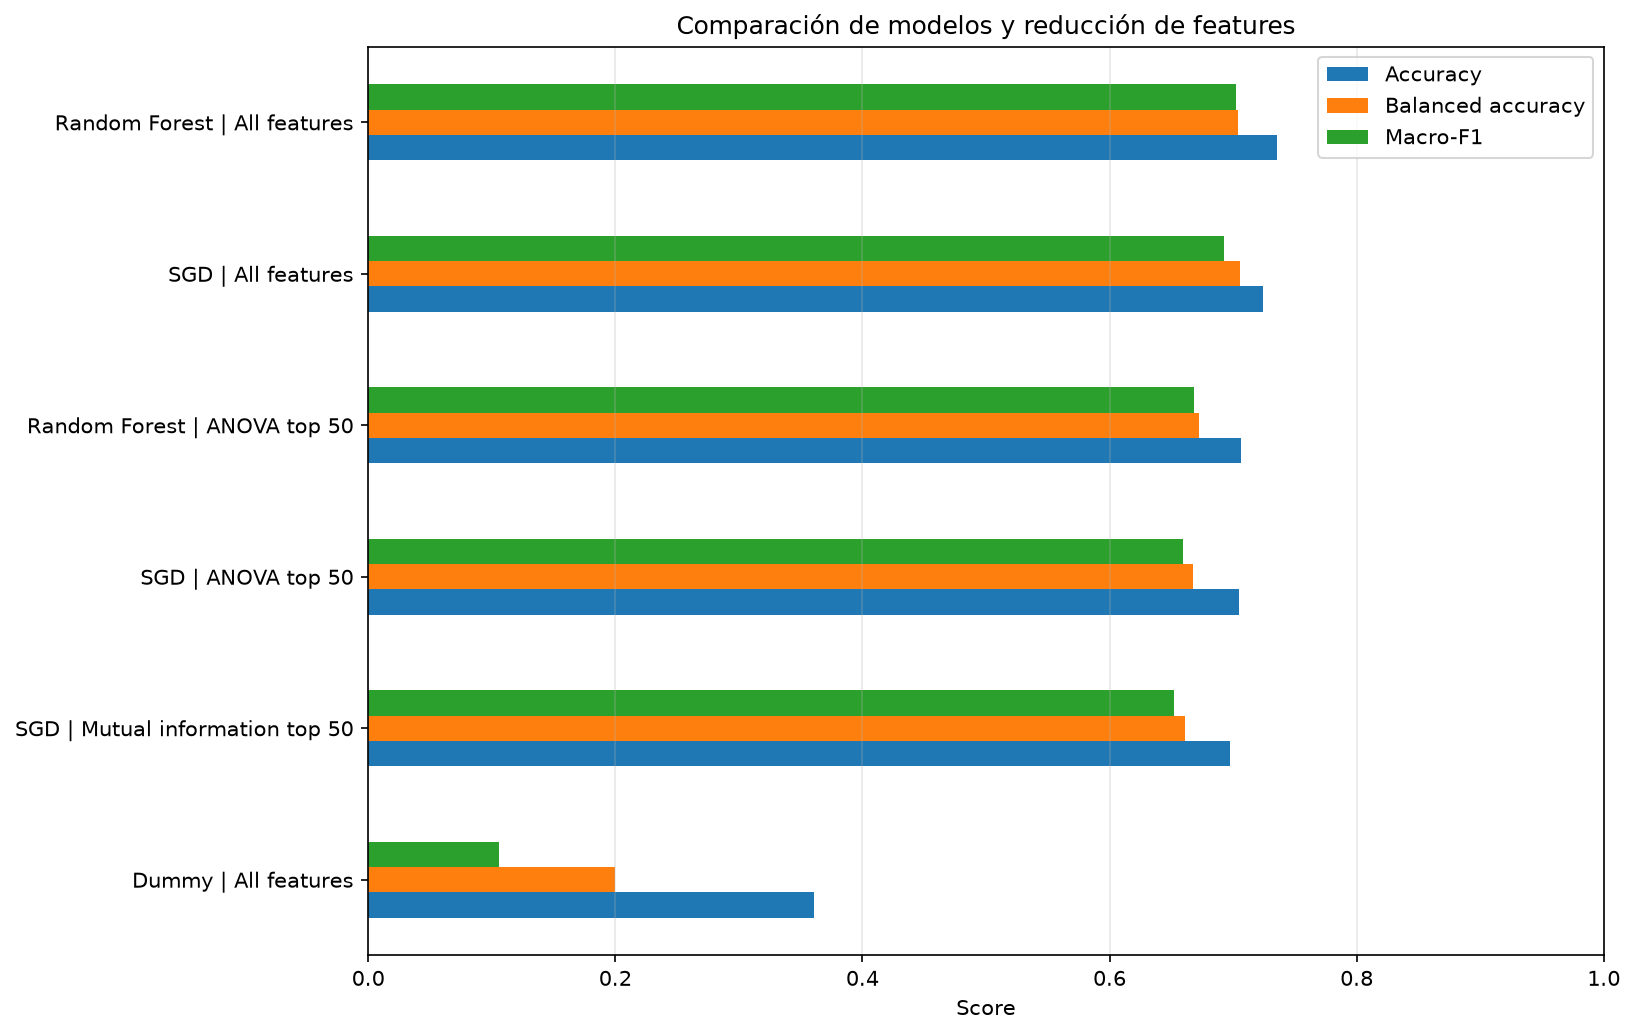

In [12]:
CV_PLOT_PATH = FIGURES_DIR / "feature_reduction_cv_comparison.png"

plot_df = (
    cv_results
    .set_index("experiment")[
        [
            "accuracy_mean",
            "balanced_accuracy_mean",
            "f1_macro_mean",
        ]
    ]
    .sort_values("f1_macro_mean")
)

fig, ax = plt.subplots(figsize=(11, 7))
plot_df.plot(kind="barh", ax=ax)

ax.set_title("Comparación de modelos y reducción de features")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)
ax.legend([
    "Accuracy",
    "Balanced accuracy",
    "Macro-F1",
])

fig.tight_layout()
fig.savefig(
    CV_PLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(CV_PLOT_PATH),
        width=1050,
    )
)


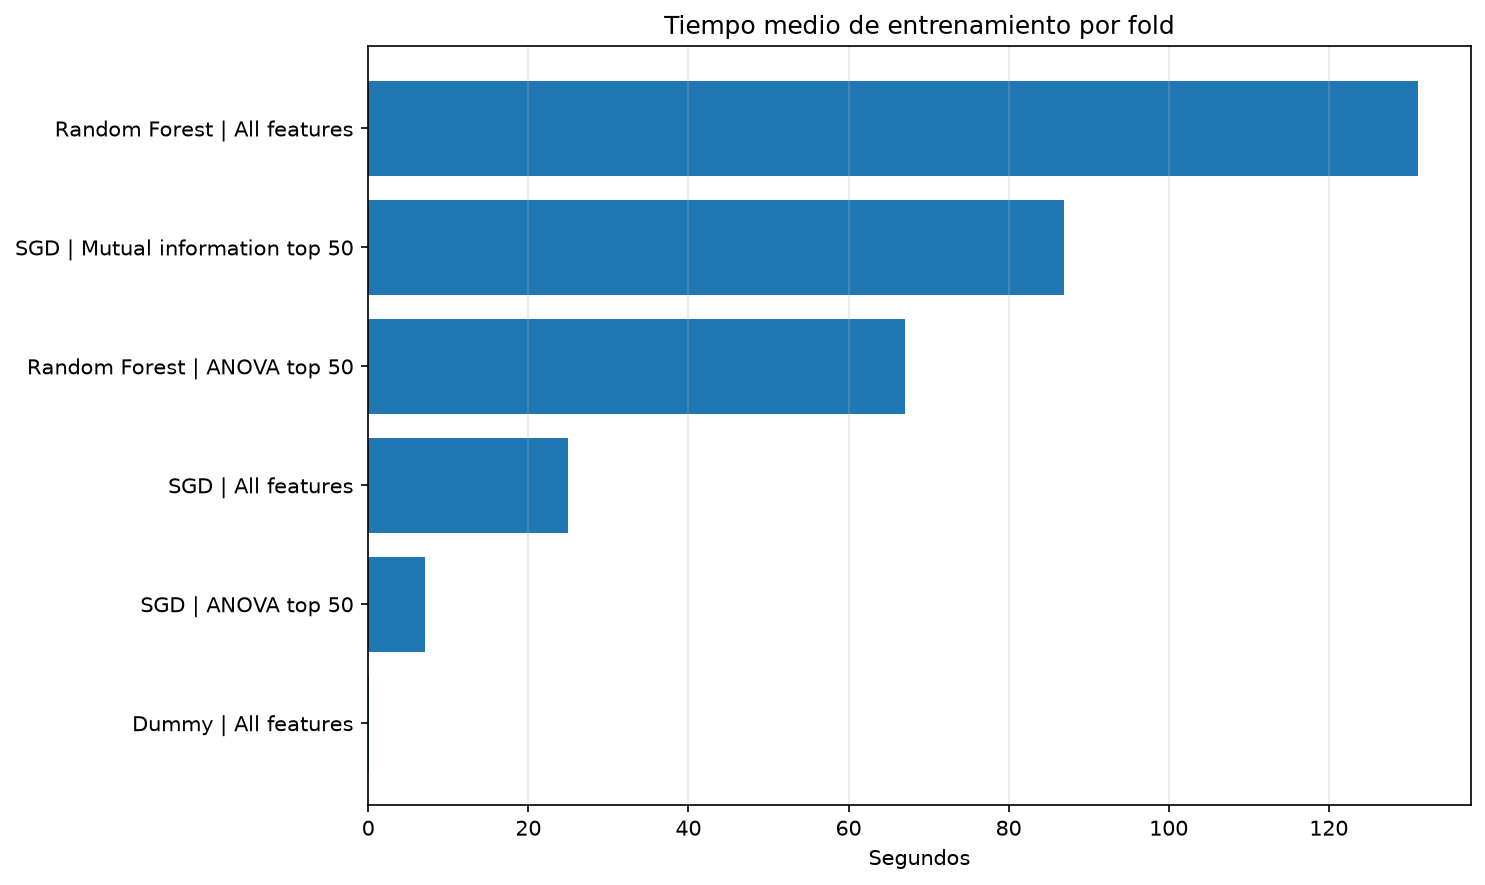

In [13]:
TIME_PLOT_PATH = FIGURES_DIR / "feature_reduction_fit_time.png"

time_df = (
    cv_results[
        ["experiment", "fit_time_mean"]
    ]
    .sort_values("fit_time_mean")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    time_df["experiment"],
    time_df["fit_time_mean"],
)

ax.set_title("Tiempo medio de entrenamiento por fold")
ax.set_xlabel("Segundos")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    TIME_PLOT_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(TIME_PLOT_PATH),
        width=950,
    )
)


---
## 6. Selección y entrenamiento final

Si varias configuraciones quedan dentro de 0.005 de Macro-F1 respecto del máximo, se prioriza la alternativa más simple e interpretable.


In [14]:
best_f1 = cv_results["f1_macro_mean"].max()

competitive = cv_results[
    cv_results["f1_macro_mean"] >= best_f1 - SELECTION_TOLERANCE
]

preferred_order = [
    "SGD | ANOVA top 50",
    "SGD | All features",
    "SGD | Mutual information top 50",
    "Random Forest | ANOVA top 50",
    "Random Forest | All features",
    "Dummy | All features",
]

best_experiment_name = next(
    name
    for name in preferred_order
    if name in competitive["experiment"].values
)

best_model = clone(
    experiments[best_experiment_name]
)

print("Mejor Macro-F1:", round(best_f1, 4))
print("Configuraciones competitivas:")
display(competitive.round(4))

print("Configuración seleccionada:", best_experiment_name)

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)


Mejor Macro-F1: 0.7024
Configuraciones competitivas:


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,131.1848,0.2354,0.7357,0.0051,0.7043,0.0066,0.7024,0.0068


Configuración seleccionada: Random Forest | All features


In [15]:
holdout_metrics = {
    "experiment": best_experiment_name,
    "accuracy": float(
        accuracy_score(y_test, y_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "f1_macro": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "n_train_epochs": int(len(X_train)),
    "n_test_epochs": int(len(X_test)),
    "n_train_subjects": int(len(train_subjects)),
    "n_test_subjects": int(len(test_subjects)),
}

display(
    pd.Series(holdout_metrics)
    .to_frame("value")
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        digits=4,
        zero_division=0,
    )
)


,value
experiment,Random Forest | All features
accuracy,0.734342
balanced_accuracy,0.70448
f1_macro,0.701136
n_train_epochs,108839
n_test_epochs,26632
n_train_subjects,119
n_test_subjects,30



Classification report:
              precision    recall  f1-score   support

           W     0.7554    0.8277    0.7899      4354
          N1     0.4129    0.3552    0.3819      3043
          N2     0.7625    0.7563    0.7594     10169
          N3     0.7964    0.7966    0.7965      5014
         REM     0.7696    0.7865    0.7780      4052

    accuracy                         0.7343     26632
   macro avg     0.6994    0.7045    0.7011     26632
weighted avg     0.7288    0.7343    0.7311     26632



### 6.1 Matriz de confusión


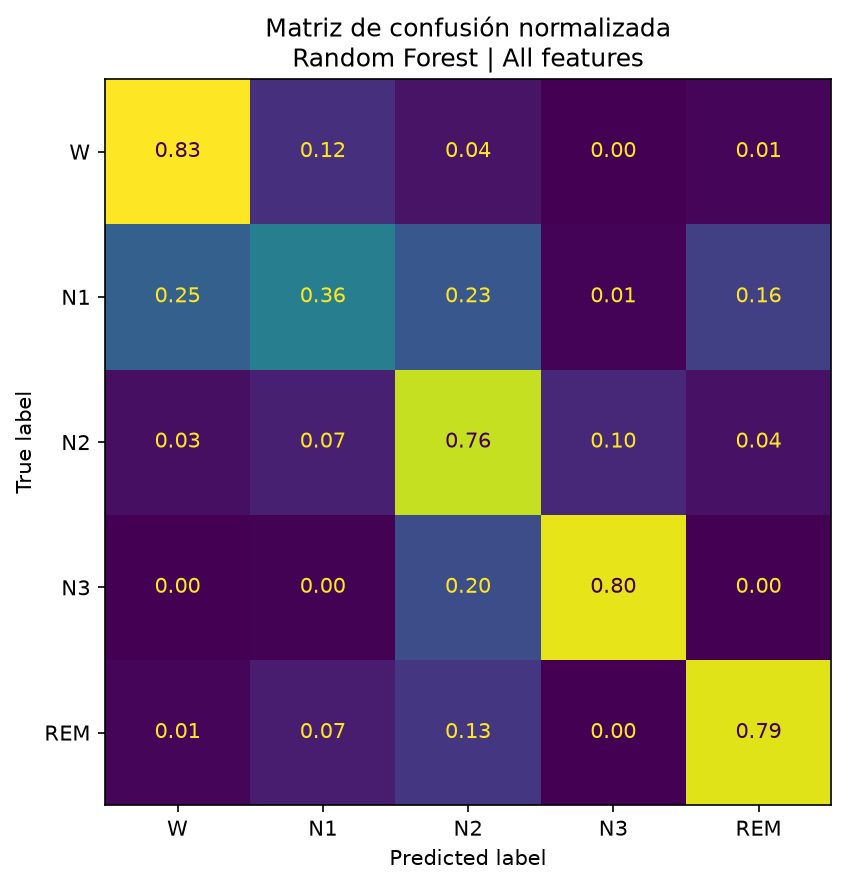

In [16]:
CONFUSION_PATH = FIGURES_DIR / "baseline_holdout_confusion_matrix.png"

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=STAGE_ORDER,
    normalize="true",
)

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=STAGE_NAMES,
)

display_cm.plot(
    ax=ax,
    values_format=".2f",
    colorbar=False,
)

ax.set_title(
    f"Matriz de confusión normalizada\n{best_experiment_name}"
)

fig.tight_layout()
fig.savefig(
    CONFUSION_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(
        filename=str(CONFUSION_PATH),
        width=700,
    )
)


---
## 7. Interpretación del modelo seleccionado


In [17]:
def transformed_feature_names(fitted_pipeline, original_features):
    """Recupera nombres luego de varianza y selección."""
    names = np.asarray(original_features)

    variance_step = fitted_pipeline.named_steps.get("variance")
    if variance_step is not None:
        names = names[variance_step.get_support()]

    selector_step = fitted_pipeline.named_steps.get("selector")
    if selector_step is not None:
        names = names[selector_step.get_support()]

    return names


def importance_table(fitted_pipeline, original_features):
    """Importancia para SGD y Random Forest."""
    estimator = fitted_pipeline.named_steps["model"]
    names = transformed_feature_names(
        fitted_pipeline,
        original_features,
    )

    if hasattr(estimator, "feature_importances_"):
        importance = estimator.feature_importances_

    elif hasattr(estimator, "coef_"):
        importance = np.abs(estimator.coef_).mean(axis=0)

    else:
        return None

    return (
        pd.DataFrame({
            "feature": names,
            "importance": importance,
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )


importance_df = importance_table(
    best_model,
    FEATURE_COLS,
)

if importance_df is None:
    print(
        "La configuración seleccionada no expone "
        "importancia directa de features."
    )
else:
    display(importance_df.head(20))


,feature,importance
0,EEG C3-M2__ratio_sigma_beta,0.036032
1,EEG C4-M1__ratio_sigma_beta,0.028896
2,EEG C4-M1__zcr,0.023485
3,EEG C3-M2__zcr,0.022649
4,EEG C3-M2__ratio_delta_beta,0.021051
5,EMG chin__power_20_35,0.020840
6,EEG F4-M1__ratio_sigma_beta,0.019415
7,EEG O2-M1__ratio_theta_alpha,0.018779
8,EMG chin__power_10_35,0.016922
9,EEG F4-M1__perm_entropy,0.015880


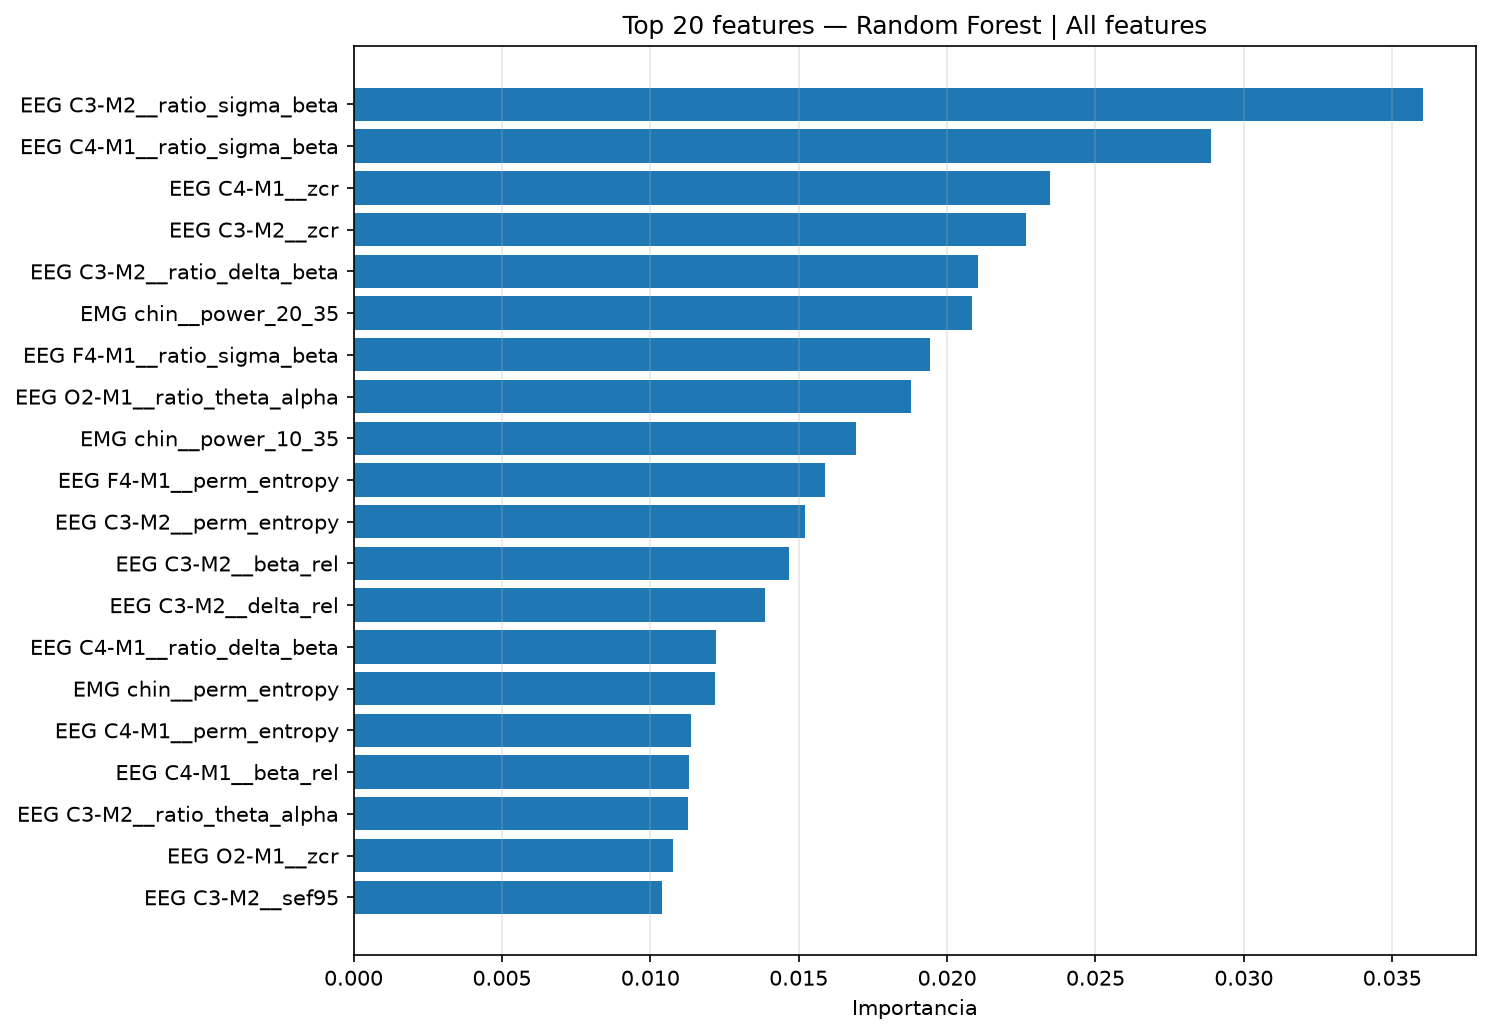

In [18]:
if importance_df is not None:
    IMPORTANCE_PATH = FIGURES_DIR / "baseline_feature_importance.png"

    top_importance = (
        importance_df
        .head(20)
        .sort_values("importance")
    )

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.barh(
        top_importance["feature"],
        top_importance["importance"],
    )

    ax.set_title(
        f"Top 20 features — {best_experiment_name}"
    )
    ax.set_xlabel("Importancia")
    ax.grid(axis="x", alpha=0.3)

    fig.tight_layout()
    fig.savefig(
        IMPORTANCE_PATH,
        dpi=150,
        bbox_inches="tight",
    )
    plt.close(fig)

    display(
        Image(
            filename=str(IMPORTANCE_PATH),
            width=950,
        )
    )


---
## 8. Guardado de artefactos


In [19]:
joblib.dump(
    {
        "model": best_model,
        "feature_names": FEATURE_COLS,
        "stage_map": STAGE_MAP,
        "experiment": best_experiment_name,
    },
    MODEL_PATH,
)

predictions_df = features_df.iloc[test_idx][
    METADATA_COLS
].copy()

predictions_df["y_true"] = y_test.to_numpy()
predictions_df["y_pred"] = y_pred

predictions_df.to_parquet(
    PREDICTIONS_PATH,
    index=False,
)

with open(
    HOLDOUT_RESULTS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        holdout_metrics,
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Modelo:", MODEL_PATH.resolve())
print("Predicciones:", PREDICTIONS_PATH.resolve())
print("Métricas:", HOLDOUT_RESULTS_PATH.resolve())


Modelo: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\models\baseline_best_model.joblib
Predicciones: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_holdout_predictions.parquet
Métricas: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\baseline_holdout_metrics.json


---
## 9. Checklist final


In [20]:
checks = {
    "Sin solapamiento de sujetos": (
        train_subjects.isdisjoint(test_subjects)
    ),
    "Metadata excluida de features": not bool(
        set(METADATA_COLS) & set(FEATURE_COLS)
    ),
    "Split por sujeto guardado": SPLIT_PATH.exists(),
    "Cross-validation guardada": CV_RESULTS_PATH.exists(),
    "Ranking Kruskal guardado": KRUSKAL_PATH.exists(),
    "Modelo guardado": MODEL_PATH.exists(),
    "Predicciones guardadas": PREDICTIONS_PATH.exists(),
    "Métricas guardadas": HOLDOUT_RESULTS_PATH.exists(),
    "Predicciones alineadas": len(y_pred) == len(y_test),
}

print("=" * 72)
print("CHECKLIST — BASELINE Y REDUCCIÓN DE FEATURES")
print("=" * 72)

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print("\nResumen:")
print(f"  configuración:       {best_experiment_name}")
print(f"  holdout accuracy:    {holdout_metrics['accuracy']:.4f}")
print(f"  balanced accuracy:   {holdout_metrics['balanced_accuracy']:.4f}")
print(f"  holdout macro-F1:    {holdout_metrics['f1_macro']:.4f}")

print("\nPróximo paso:")
print("  Probar modelos de boosting bajo el mismo split por sujeto.")


CHECKLIST — BASELINE Y REDUCCIÓN DE FEATURES
✅  Sin solapamiento de sujetos
✅  Metadata excluida de features
✅  Split por sujeto guardado
✅  Cross-validation guardada
✅  Ranking Kruskal guardado
✅  Modelo guardado
✅  Predicciones guardadas
✅  Métricas guardadas
✅  Predicciones alineadas

Resumen:
  configuración:       Random Forest | All features
  holdout accuracy:    0.7343
  balanced accuracy:   0.7045
  holdout macro-F1:    0.7011

Próximo paso:
  Probar modelos de boosting bajo el mismo split por sujeto.
